# Surrogate local con región de confianza para FWI — prueba de juguete 2D

Este notebook implementa el lazo descrito en la propuesta:

* **Solver "caro"** (sustituto de SPECFEM3D): ecuación de onda acústica 2D en diferencias finitas
  (4º orden en espacio, 2º en tiempo, bordes absorbentes tipo *sponge*) escrita en PyTorch.
  - forward → $F(m)$, $r_k$
  - adjunto → $g_k = B_k^\top r_k$ (aquí vía autograd, que es exactamente el método adjunto discreto)
  - Born → $B_k v$ (aquí vía `torch.func.jvp`, modo forward)
  Cada llamada se **cuenta** como una simulación.
* **Surrogate local** $\tilde F_k(s) = F(m_k) + U c + P\,h_\phi(c)$, con $s = Vc$, consistencia de primer
  orden por corrección aditiva, y $h_\phi(0)=0,\ \nabla h_\phi(0)=0$.
* **Región de confianza** en la norma ponderada $\|s\|_W$ = cambio relativo RMS de velocidad.
* **Comparación** contra L-BFGS (estilo SeisFlows: ensayos de búsqueda lineal = solo forward,
  adjunto solo en el punto aceptado) con el **mismo presupuesto de simulaciones**.

In [1]:
import math, time
from dataclasses import dataclass, field

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as Fnn
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

torch.manual_seed(0)
np.random.seed(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DT = torch.float32
print("device:", dev)

device: cuda


## 1. Malla, adquisición y solver de onda (el "SPECFEM3D" de juguete)

In [2]:
nz, nx, dx = 60, 100, 0.020          # km  (1.2 km x 2.0 km)
nt, dt, f0 = 700, 0.002, 5.0         # s, Hz  (registro de 1.4 s)
npml = 20
NZ, NX = nz + 2 * npml, nx + 2 * npml

src_x = np.linspace(4, nx - 5, 6).round().astype(int)
src_z, rec_z = 2, 2                  # fuentes y una línea de receptores cerca de la superficie
well_l, well_r = 2, nx - 3           # + dos pozos con receptores (geometría bien iluminada para el juguete)
ns = len(src_x)
nrec = nx + 2 * nz

tt = np.arange(nt) * dt
def ricker(f, t, t0):
    a = (np.pi * f * (t - t0)) ** 2
    return (1 - 2 * a) * np.exp(-a)
wavelet = torch.tensor(ricker(f0, tt, 1.2 / f0), dtype=DT, device=dev)

S = torch.zeros(ns, NZ, NX, dtype=DT, device=dev)
for i, sx in enumerate(src_x):
    S[i, npml + src_z, npml + sx] = 1.0

VMIN, VMAX = 1.2, 3.2
sig_max = 3 * VMAX * np.log(1e3) / (2 * npml * dx)
prof = sig_max * (np.arange(npml, 0, -1) / npml) ** 2
sig = np.zeros((NZ, NX))
for i in range(npml):
    sig[i, :] = np.maximum(sig[i, :], prof[i]); sig[NZ - 1 - i, :] = np.maximum(sig[NZ - 1 - i, :], prof[i])
    sig[:, i] = np.maximum(sig[:, i], prof[i]); sig[:, NX - 1 - i] = np.maximum(sig[:, NX - 1 - i], prof[i])
sig = torch.tensor(sig, dtype=DT, device=dev)
A_damp, B_damp = 1 + sig * dt / 2, 1 - sig * dt / 2
print(f"CFL max = {VMAX * dt / dx:.2f}  |  puntos por longitud de onda mínima ≈ {VMIN / (2.5 * f0) / dx:.1f}")


def lap4(u):
    up = Fnn.pad(u, (2, 2, 2, 2))
    c = up[:, 2:-2, 2:-2]
    lz = (-1 / 12) * (up[:, :-4, 2:-2] + up[:, 4:, 2:-2]) + (4 / 3) * (up[:, 1:-3, 2:-2] + up[:, 3:-1, 2:-2])
    lx = (-1 / 12) * (up[:, 2:-2, :-4] + up[:, 2:-2, 4:]) + (4 / 3) * (up[:, 2:-2, 1:-3] + up[:, 2:-2, 3:-1])
    return lz + lx - 5.0 * c


def simulate(v):
    """v: (nz, nx) velocidad [km/s] -> sismogramas (ns, nt, nrec)."""
    vp = Fnn.pad(v[None, None], (npml,) * 4, mode="replicate")[0, 0]
    c2 = (vp * dt / dx) ** 2
    u0 = torch.zeros(ns, NZ, NX, dtype=DT, device=dev)
    u1 = torch.zeros_like(u0)
    traces = []
    for it in range(nt):
        u2 = (2 * u1 - B_damp * u0 + c2 * lap4(u1) + (dt ** 2) * wavelet[it] * S) / A_damp
        traces.append(torch.cat([u2[:, npml + rec_z, npml:npml + nx],
                                 u2[:, npml:npml + nz, npml + well_l],
                                 u2[:, npml:npml + nz, npml + well_r]], 1))
        u0, u1 = u1, u2
    return torch.stack(traces, 1)

CFL max = 0.32  |  puntos por longitud de onda mínima ≈ 4.8


## 2. Modelo verdadero, modelo inicial y datos observados

datos: (6, 700, 220)  (n_d = 924,000),  n_m = 6,000 (4,386.0 activos)
tiempo de una simulación forward: 0.27 s


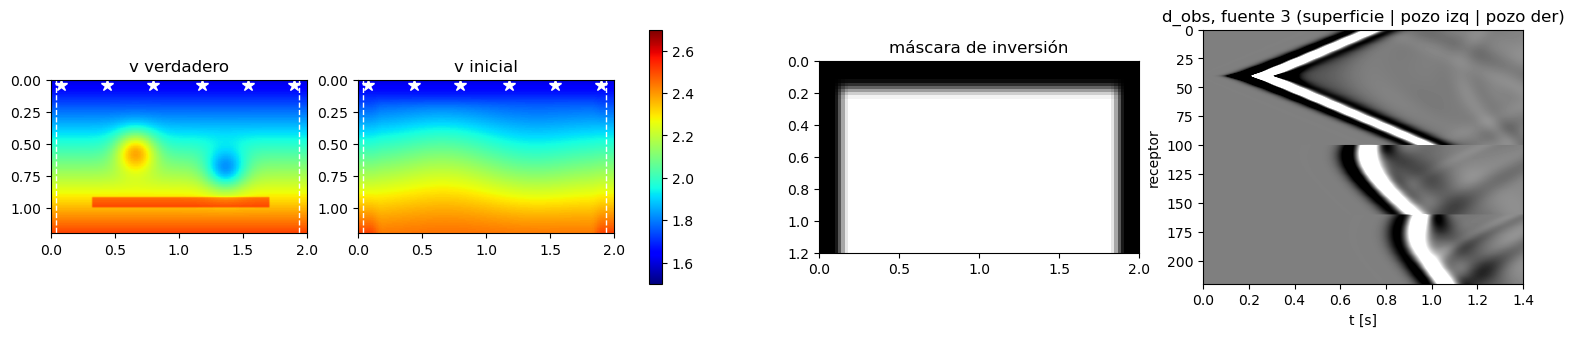

In [3]:
zz, xx = np.meshgrid(np.arange(nz) * dx, np.arange(nx) * dx, indexing="ij")
v_true_np = 1.6 + 0.9 * zz / zz.max()
v_true_np += 0.35 * np.exp(-((xx - 0.65) ** 2 + (zz - 0.55) ** 2) / (2 * 0.11 ** 2))
v_true_np -= 0.30 * np.exp(-((xx - 1.35) ** 2 + (zz - 0.70) ** 2) / (2 * 0.11 ** 2))
v_true_np += 0.15 * (np.abs(zz - 0.95) < 0.04) * (xx > 0.3) * (xx < 1.7)
v_smooth_np = gaussian_filter(v_true_np, sigma=12, mode="nearest")

def taper1d(n, i0, i1):
    """0 antes de i0, rampa coseno hasta i1, 1 después."""
    t = np.clip((np.arange(n) - i0) / (i1 - i0), 0, 1)
    return 0.5 - 0.5 * np.cos(np.pi * t)

tz = taper1d(nz, 5, 12)
tx = np.minimum(taper1d(nx, 4, 9), taper1d(nx, 4, 9)[::-1])
mask_np = tz[:, None] * tx[None, :]                       # no se invierte junto a fuentes/pozos
# Modelo inicial: suavizado dentro de la zona invertida; se supone conocido en la zona no invertida.
v_init_np = mask_np * v_smooth_np + (1 - mask_np) * v_true_np

v_true = torch.tensor(v_true_np, dtype=DT, device=dev)
v_init = torch.tensor(v_init_np, dtype=DT, device=dev)
mask = torch.tensor(mask_np, dtype=DT, device=dev)
n_act = float(mask.sum())

with torch.no_grad():
    t0 = time.time(); d_raw = simulate(v_true); torch.cuda.synchronize() if dev.type == "cuda" else None
    t_fwd = time.time() - t0
DSCALE = d_raw.abs().max().item()
d_obs = d_raw / DSCALE
print(f"datos: {tuple(d_obs.shape)}  (n_d = {d_obs.numel():,}),  n_m = {nz * nx:,} ({n_act:,} activos)")
print(f"tiempo de una simulación forward: {t_fwd:.2f} s")


def rel_err(v):
    return (((v - v_true) / v_true) ** 2 * mask).sum().div(n_act).sqrt().item()


fig, ax = plt.subplots(1, 4, figsize=(19, 3.3))
ext = [0, nx * dx, nz * dx, 0]
for a, img, ttl in zip(ax[:2], [v_true_np, v_init_np], ["v verdadero", "v inicial"]):
    im = a.imshow(img, extent=ext, cmap="jet", vmin=1.5, vmax=2.7); a.set_title(ttl)
    a.plot(src_x * dx, np.full(ns, src_z * dx), "w*", ms=9)
    a.plot([well_l * dx] * 2, [0, nz * dx], "w--", [well_r * dx] * 2, [0, nz * dx], "w--", lw=1)
plt.colorbar(im, ax=ax[:2])
ax[2].imshow(mask.cpu(), extent=ext, cmap="gray"); ax[2].set_title("máscara de inversión")
ax[3].imshow(d_obs[2].cpu().T, aspect="auto", cmap="gray", vmin=-0.05, vmax=0.05, extent=[0, nt * dt, nrec, 0])
ax[3].set_title("d_obs, fuente 3 (superficie | pozo izq | pozo der)"); ax[3].set_xlabel("t [s]"); ax[3].set_ylabel("receptor")
plt.show()

## 3. Interfaz de "simulaciones caras" con contador

Regla de costo (igual para todos los métodos):
* `forward` = 1 simulación. Se puede guardar el estado para un adjunto posterior (como `SAVE_FORWARD` en SPECFEM).
* `adjoint` = 1 simulación (solo en puntos aceptados).
* `born` = 1 simulación (producto jacobiano-vector exacto).

Si se prefiere la contabilidad más conservadora de la propuesta (forward + adjunto = 2 *después* de la verificación),
poner `CHARGE_REFORWARD = True`: cada adjunto cobrará además un forward.

In [4]:
CHARGE_REFORWARD = False


class ExpensiveSolver:
    def __init__(self, d_obs):
        self.d_obs = d_obs
        self.n_fwd = self.n_adj = self.n_born = 0
        self.trace = []                       # (n_sims, J) en cada forward

    @property
    def n_sims(self):
        return self.n_fwd + self.n_adj + self.n_born

    def _F(self, m):
        return simulate(m.clamp(VMIN, VMAX)) / DSCALE

    def forward(self, m, keep=False):
        self.n_fwd += 1
        if keep:
            m = m.detach().requires_grad_(True)
            d = self._F(m)
            J = 0.5 * ((d - self.d_obs) ** 2).sum()
            self.trace.append((self.n_sims, J.item()))
            return J.item(), d.detach(), (m, J)
        with torch.no_grad():
            d = self._F(m)
            J = 0.5 * ((d - self.d_obs) ** 2).sum().item()
        self.trace.append((self.n_sims, J))
        return J, d, None

    def adjoint(self, handle):
        self.n_adj += 1 + int(CHARGE_REFORWARD)
        m, J = handle
        (g,) = torch.autograd.grad(J, m)
        return g

    def born(self, m, v):
        self.n_born += 1
        _, Bv = torch.func.jvp(self._F, (m.detach(),), (v.detach(),))
        return Bv

### Comprobación: Born (JVP) vs diferencias finitas y gradiente adjunto vs diferencias finitas

In [5]:
chk = ExpensiveSolver(d_obs)
vdir = torch.randn(nz, nx, device=dev).mul(mask)
vdir = torch.tensor(gaussian_filter(vdir.cpu().numpy(), 3), device=dev) * mask
vdir = vdir / vdir.abs().max() * 0.05
Bv = chk.born(v_init, vdir)
eps = 0.1
with torch.no_grad():
    fd = (chk._F(v_init + eps * vdir) - chk._F(v_init - eps * vdir)) / (2 * eps)
print("Born vs DF, error relativo:", ((Bv - fd).norm() / fd.norm()).item())
J0, d0, h0 = chk.forward(v_init, keep=True)
g0 = chk.adjoint(h0)
Jp, _, _ = chk.forward(v_init + eps * vdir); Jm, _, _ = chk.forward(v_init - eps * vdir)
print(f"<g, v> adjunto = {(g0 * vdir).sum().item():.6e}   DF = {(Jp - Jm) / (2 * eps):.6e}")
del h0

Born vs DF, error relativo: 0.0003821632999461144


<g, v> adjunto = -5.485151e-01   DF = -5.482697e-01


## 4. Parametrización, norma ponderada y subespacio

Variables "hat": $s = D\odot(G\hat s)$, con $G$ un suavizado gaussiano (preconditionador, el mismo para todos los métodos)
y $D = \text{mask}\cdot v_0\sqrt{n_{act}}$. Así $\|\hat s\|_2$ ≈ **cambio relativo RMS de velocidad** en las celdas activas,
que es la norma $\|\cdot\|_W$ de la región de confianza. El gradiente en esas variables es $\hat g = G(D\odot g)$.

$V = D\odot G\hat V$ con $\hat V^\top\hat V = I$, así que la restricción $\|Vc\|_W\le\Delta$ es simplemente $\|c\|_2\le\Delta$
y $\nabla_c J(m_k) = \hat V^\top \hat g_k$.

In [6]:
SMOOTH_SIGMA = 2.0                      # celdas
Dsc = mask * v_init * math.sqrt(n_act)
_PAD = int(3 * SMOOTH_SIGMA)
_k1 = torch.exp(-torch.arange(-_PAD, _PAD + 1, device=dev, dtype=DT) ** 2 / (2 * SMOOTH_SIGMA ** 2))
_K = ((_k1[:, None] * _k1[None, :]) / _k1.sum() ** 2)[None, None]


def smooth(a):
    return Fnn.conv2d(a[None, None], _K, padding=_PAD)[0, 0]     # simétrico ⇒ autoadjunto


def to_hat_grad(g):
    return smooth(g * Dsc).flatten()


def from_hat(xh):
    return Dsc * smooth(xh.view(nz, nx))


def build_basis(cands, kmax, tol=1e-2):
    Q = []
    for v in cands:
        v0n = v.norm()
        if v0n == 0:
            continue
        w = v.clone()
        for _ in range(2):
            for q in Q:
                w -= (q @ w) * q
        if w.norm() > tol * v0n:
            Q.append(w / w.norm())
        if len(Q) == kmax:
            break
    return torch.stack(Q, 1)

## 5. El surrogate local

$$\tilde J_k(c)=\tfrac12\|r_k+Uc+P\,h_\phi(c)\|^2+(g_c-U^\top r_k)^\top c,\qquad g_c=\hat V^\top\hat g_k$$

* $U$ (parte lineal, imita $B_k V$): mínimos cuadrados ponderados con ridge sobre los pares
  (secantes $(c_i,\delta d_i)$ + pares Born $(c_v, B v)$). Con $N_\phi=0$ esto es exactamente la
  **aproximación multi-secante del jacobiano** y $\tilde J_k$ es el modelo de Gauss-Newton $\tfrac12 c^\top U^\top U c + g_c^\top c$.
* $N_\phi(c) = P\,h_\phi(c)$, con $h_\phi(c) = \text{MLP}(c) - \text{MLP}(0) - \nabla\text{MLP}(0)\,c$
  (así $N_\phi(0)=0$ y $\nabla N_\phi(0)=0$ por construcción). Se ajusta a los residuos de la parte lineal por
  *variable projection*: $P$ en forma cerrada (ridge), $\phi$ con Adam.

In [7]:
@dataclass
class Pair:
    shat: torch.Tensor      # paso en variables hat (n_m,)
    dd: torch.Tensor        # cambio de datos (n_d,)
    kind: str               # "secant" | "born"
    it: int                 # iteración en que se generó
    base_hat: torch.Tensor  # punto base en variables hat


class Surrogate(nn.Module):
    def __init__(self, k, r=3, hidden=32):
        super().__init__()
        self.k, self.r = k, r
        self.mlp = nn.Sequential(nn.Linear(k, hidden), nn.Tanh(), nn.Linear(hidden, r)).to(dev)
        self.U = None
        self.P = None

    def h(self, c):
        z = torch.zeros(self.k, device=dev)
        J0 = torch.func.jacrev(self.mlp)(z)                    # (r, k)
        return self.mlp(c) - self.mlp(z) - c @ J0.T

    def delta_d(self, c):
        out = self.U @ c
        if self.P is not None:
            out = out + self.P @ self.h(c)
        return out


def pair_weights(pairs, C, Shat, it, x_hat, Delta, cfg):
    w = []
    for i, p in enumerate(pairs):
        age = it - p.it
        dist = (p.base_hat - x_hat).norm().item()
        proj = (C[:, i].norm() / Shat[:, i].norm()).item() ** 2   # fracción del paso dentro de span(V)
        wi = cfg.decay ** age / (1 + (dist / max(Delta, 1e-6)) ** 2) * proj
        w.append(wi * (cfg.born_weight if p.kind == "born" else 1.0))
    return torch.tensor(w, device=dev, dtype=DT)


def fit_surrogate(pairs, Vhat, it, x_hat, Delta, cfg):
    k = Vhat.shape[1]
    sur = Surrogate(k, r=cfg.nl_rank)
    nd = d_obs.numel()
    if len(pairs) == 0:
        sur.U = torch.zeros(nd, k, device=dev)
        return sur, {}
    Shat = torch.stack([p.shat for p in pairs], 1)
    Dd = torch.stack([p.dd for p in pairs], 1)
    C = Vhat.T @ Shat                                           # (k, np)
    w = pair_weights(pairs, C, Shat, it, x_hat, Delta, cfg)
    G = (C * w) @ C.T
    lam = cfg.ridge * torch.trace(G) / k + 1e-12
    sur.U = torch.linalg.solve(G + lam * torch.eye(k, device=dev), ((Dd * w) @ C.T).T).T
    info = {}
    sec = [i for i, p in enumerate(pairs) if p.kind == "secant"]
    if cfg.use_nl and len(sec) >= cfg.nl_min_pairs:
        Cs, Rs, ws = C[:, sec], Dd[:, sec] - sur.U @ C[:, sec], w[sec]
        opt = torch.optim.Adam(sur.mlp.parameters(), lr=1e-2)
        scale = Cs.norm(dim=0).max().clamp_min(1e-8)
        def fitP():
            H = sur.h((Cs / scale).T).T                         # (r, ns)
            Gh = (H * ws) @ H.T
            lamh = cfg.nl_ridge * torch.trace(Gh) / sur.r + 1e-12
            P = torch.linalg.solve(Gh + lamh * torch.eye(sur.r, device=dev), ((Rs * ws) @ H.T).T).T
            loss = (((P @ H - Rs) ** 2).sum(0) * ws).sum()
            return P, loss
        for _ in range(cfg.nl_epochs):
            opt.zero_grad(); _, loss = fitP(); loss.backward(); opt.step()
        with torch.no_grad():
            P, loss = fitP()
        r0 = ((Rs ** 2).sum(0) * ws).sum().item()
        info = {"nl_residual_drop": 1 - loss.item() / max(r0, 1e-30)}
        mlp0 = sur.mlp
        sur.mlp = nn.Sequential(_Scale(1 / scale), mlp0)          # h usa c/scale
        sur.P = P.detach()
        for p in sur.mlp.parameters():
            p.requires_grad_(False)
    return sur, info


class _Scale(nn.Module):
    def __init__(self, s):
        super().__init__(); self.s = s
    def forward(self, x):
        return x * self.s


def make_Jtilde(sur, r, gc):
    corr = gc - sur.U.T @ r
    def Jt(c):
        res = r + sur.delta_d(c)
        return 0.5 * (res ** 2).sum() + corr @ c
    return Jt

### Comprobación de consistencia de primer orden: $\nabla\tilde J_k(0)=g_c$ aunque $U$ y $N_\phi$ sean arbitrarios

In [8]:
_k = 5
_sur = Surrogate(_k); _sur.U = torch.randn(d_obs.numel(), _k, device=dev); _sur.P = torch.randn(d_obs.numel(), 3, device=dev)
_r, _gc = torch.randn(d_obs.numel(), device=dev), torch.randn(_k, device=dev)
_c = torch.zeros(_k, device=dev, requires_grad=True)
make_Jtilde(_sur, _r, _gc)(_c).backward()
print("max |∇J̃(0) - g_c| / max|g_c| =", ((_c.grad - _gc).abs().max() / _gc.abs().max()).item())

max |∇J̃(0) - g_c| / max|g_c| = 2.5401519451406784e-05


## 6. Subproblema interno (sin simulaciones): Cauchy + Adam proyectado sobre la bola

In [9]:
def solve_subproblem(Jt, gc, Delta, iters=300):
    J0 = Jt(torch.zeros_like(gc)).item()
    # punto de Cauchy: búsqueda 1D a lo largo de -g_c dentro de la región
    p = -gc / gc.norm()
    ts = torch.linspace(0, Delta, 65, device=dev)[1:]
    with torch.no_grad():
        vals = torch.stack([Jt(t * p) for t in ts])
    c_cau = ts[vals.argmin()] * p
    J_cau = vals.min().item()
    # Adam proyectado partiendo del punto de Cauchy
    c = c_cau.clone().requires_grad_(True)
    opt = torch.optim.Adam([c], lr=Delta / 20)
    best_c, best_J = c_cau.clone(), J_cau
    for _ in range(iters):
        opt.zero_grad()
        J = Jt(c)
        if J.item() < best_J:
            best_J, best_c = J.item(), c.detach().clone()
        J.backward(); opt.step()
        with torch.no_grad():
            n = c.norm()
            if n > Delta:
                c.mul_(Delta / n)
    with torch.no_grad():
        Jl = Jt(c).item()
        if Jl < best_J:
            best_J, best_c = Jl, c.detach().clone()
    return best_c, J0 - best_J, J0 - J_cau


def traveltime_cap(s, v):
    """Desfase vertical de ida y vuelta (por columna) inducido por el paso, para el tope heurístico T/4."""
    dtcol = 2 * (-(s / v ** 2) * dx).sum(0)
    return dtcol.abs().max().item()

## 7. Lazo de región de confianza

In [10]:
@dataclass
class TRConfig:
    budget: int = 100
    Delta0: float = 0.01
    Delta_max: float = 0.06
    eta1: float = 0.1
    eta2: float = 0.75
    gamma_dec: float = 0.5
    gamma_inc: float = 2.0
    kmax: int = 10
    n_steps_basis: int = 7
    n_grads_basis: int = 2
    decay: float = 0.8
    ridge: float = 1e-3
    born_weight: float = 1.0
    use_born: bool = True
    use_nl: bool = False
    nl_rank: int = 3
    nl_min_pairs: int = 4
    nl_ridge: float = 1e-2
    nl_epochs: int = 150
    inner_iters: int = 300
    tt_cap: float = 1 / (4 * f0)      # desfase máximo (s)
    verbose: bool = True


def run_trust_region(cfg, label="TR"):
    solver = ExpensiveSolver(d_obs)
    m = v_init.clone()
    x_hat = torch.zeros(nz * nx, device=dev)
    J, d, h = solver.forward(m, keep=True)
    g = solver.adjoint(h); del h
    ghat = to_hat_grad(g)
    Delta = cfg.Delta0
    pairs, steps, grads = [], [], [ghat]
    log = []
    if cfg.use_born:
        v_dir = ghat / ghat.norm() * Delta
        pairs.append(Pair(v_dir, solver.born(m, from_hat(v_dir)).flatten(), "born", 0, x_hat.clone()))
    it = 0
    while solver.n_sims < cfg.budget:
        it += 1
        r = (d - d_obs).flatten()
        cands = [ghat] + steps[::-1][: cfg.n_steps_basis] + grads[-2::-1][: cfg.n_grads_basis]
        Vhat = build_basis(cands, cfg.kmax)
        sur, info = fit_surrogate(pairs, Vhat, it, x_hat, Delta, cfg)
        gc = Vhat.T @ ghat
        Jt = make_Jtilde(sur, r, gc)
        c, pred, pred_cau = solve_subproblem(Jt, gc, Delta, cfg.inner_iters)
        shat = Vhat @ c
        s = from_hat(shat)
        dtmax = traveltime_cap(s, m)
        if dtmax > cfg.tt_cap:                              # tope heurístico anti cycle-skipping
            fac = cfg.tt_cap / dtmax
            c = c * fac; shat = shat * fac; s = s * fac
            with torch.no_grad():
                pred = Jt(torch.zeros_like(c)).item() - Jt(c).item()
        J_new, d_new, h_new = solver.forward(m + s, keep=True)      # 1 simulación de verificación
        ared = J - J_new
        rho = ared / pred if pred > 0 else -np.inf
        pairs.append(Pair(shat.detach(), (d_new - d).flatten(), "secant", it, x_hat.clone()))
        steps.append(shat.detach())
        accepted = rho >= cfg.eta1
        log.append(dict(it=it, sims=solver.n_sims, J=J, J_trial=J_new, pred=pred, pred_cauchy=pred_cau,
                        ared=ared, rho=rho, Delta=Delta, k=Vhat.shape[1], cnorm=c.norm().item(),
                        accepted=accepted, err=rel_err(m), **info))
        # actualización del radio
        if rho < cfg.eta1:
            Delta *= cfg.gamma_dec
        elif rho >= cfg.eta2 and c.norm().item() >= 0.9 * Delta:
            Delta = min(cfg.gamma_inc * Delta, cfg.Delta_max)
        if accepted:
            m = m + s; x_hat = x_hat + shat; J, d = J_new, d_new
            if solver.n_sims >= cfg.budget:
                break
            g = solver.adjoint(h_new)
            ghat = to_hat_grad(g); grads.append(ghat)
            if cfg.use_born and solver.n_sims < cfg.budget:
                v_dir = ghat / ghat.norm() * Delta
                pairs.append(Pair(v_dir, solver.born(m, from_hat(v_dir)).flatten(), "born", it, x_hat.clone()))
        del h_new
        if cfg.verbose:
            e = log[-1]
            print(f"[{label}] it {it:3d} sims {e['sims']:4d}  J {e['J']:.4e} -> {e['J_trial']:.4e}  "
                  f"rho {e['rho']:+.2f}  Δ {e['Delta']:.4f}  k {e['k']:2d}  {'ACEPTA' if accepted else 'rechaza'}"
                  + (f"  nl↓{info['nl_residual_drop']:.2f}" if 'nl_residual_drop' in info else ""))
    return dict(label=label, m=m, log=log, solver=solver, err=rel_err(m), J=J)

## 8. Línea base: L-BFGS (estilo SeisFlows) con el mismo presupuesto

Mismas variables escaladas $\hat x$, mismo primer paso ($\|\hat s\| = \Delta_0$), mismo tope $\Delta_{max}$ por paso.
Ensayos de búsqueda lineal (Armijo + backtracking) = 1 forward; adjunto solo en el punto aceptado.

In [11]:
def run_lbfgs(budget, mem=8, step0=0.01, step_max=0.06, c1=1e-4, max_ls=6, verbose=True, label="L-BFGS"):
    solver = ExpensiveSolver(d_obs)
    x = torch.zeros(nz * nx, device=dev)
    J, _, h = solver.forward(v_init, keep=True)
    g = to_hat_grad(solver.adjoint(h)); del h
    Sm, Ym, log, it = [], [], [], 0
    while solver.n_sims < budget:
        it += 1
        q = g.clone(); al = []
        for s_, y_ in zip(reversed(Sm), reversed(Ym)):
            a = (s_ @ q) / (y_ @ s_); al.append(a); q -= a * y_
        if Sm:
            q *= (Sm[-1] @ Ym[-1]) / (Ym[-1] @ Ym[-1])
            for (s_, y_), a in zip(zip(Sm, Ym), reversed(al)):
                b = (y_ @ q) / (y_ @ s_); q += (a - b) * s_
            p = -q
        else:
            p = -g / g.norm() * step0
        if p.norm() > step_max:
            p = p / p.norm() * step_max
        if g @ p >= 0:
            Sm, Ym = [], []; p = -g / g.norm() * step0
        alpha, ok = 1.0, False
        for _ in range(max_ls):
            if solver.n_sims >= budget:
                break
            J_try, _, h = solver.forward(v_init + from_hat(x + alpha * p), keep=True)
            if J_try <= J + c1 * alpha * (g @ p).item():
                ok = True; break
            del h; alpha *= 0.5
        if not ok:
            Sm, Ym = [], []
            if solver.n_sims >= budget: break
            continue
        x_new = x + alpha * p
        log.append(dict(it=it, sims=solver.n_sims, J=J_try, alpha=alpha, err=rel_err(v_init + from_hat(x_new))))
        if solver.n_sims >= budget:
            x, J = x_new, J_try; break
        g_new = to_hat_grad(solver.adjoint(h)); del h
        s_, y_ = x_new - x, g_new - g
        if (s_ @ y_) > 1e-10 * s_.norm() * y_.norm():
            Sm.append(s_); Ym.append(y_)
            if len(Sm) > mem: Sm.pop(0); Ym.pop(0)
        x, g, J = x_new, g_new, J_try
        if verbose:
            print(f"[{label}] it {it:3d} sims {solver.n_sims:4d}  J {J:.4e}  alpha {alpha:.3f}  err {log[-1]['err']:.4f}")
    m = v_init + from_hat(x)
    return dict(label=label, m=m, log=log, solver=solver, err=rel_err(m), J=J)

## 9. Experimentos

Tres variantes del surrogate + L-BFGS, todas con el mismo presupuesto de simulaciones:

| Variante | Born | $N_\phi$ |
|---|---|---|
| TR-secante | no | no (multi-secante puro) |
| TR-Born | sí (en dirección $g_k$ tras cada aceptación) | no |
| TR-Born-NL | sí | MLP pequeño |

In [12]:
BUDGET = 100
results = {}
t0 = time.time()
results["L-BFGS"] = run_lbfgs(BUDGET, verbose=False)
print(f"L-BFGS: J={results['L-BFGS']['J']:.4e}  err={results['L-BFGS']['err']:.4f}  ({time.time() - t0:.0f} s)")
for label, kw in [("TR-secante", dict(use_born=False, use_nl=False)),
                  ("TR-Born", dict(use_born=True, use_nl=False)),
                  ("TR-Born-NL", dict(use_born=True, use_nl=True))]:
    t0 = time.time()
    results[label] = run_trust_region(TRConfig(budget=BUDGET, verbose=False, **kw), label=label)
    R = results[label]
    nacc = sum(e["accepted"] for e in R["log"])
    print(f"{label}: J={R['J']:.4e}  err={R['err']:.4f}  iters={len(R['log'])} aceptadas={nacc}  ({time.time() - t0:.0f} s)")

L-BFGS: J=2.5638e-03  err=0.0069  (96 s)


TR-secante: J=3.3141e-03  err=0.0071  iters=53 aceptadas=46  (131 s)


TR-Born: J=2.9292e-03  err=0.0070  iters=33 aceptadas=33  (187 s)


TR-Born-NL: J=3.2059e-03  err=0.0071  iters=34 aceptadas=32  (279 s)


## 10. Resultados: misfit y error de modelo frente al número de simulaciones

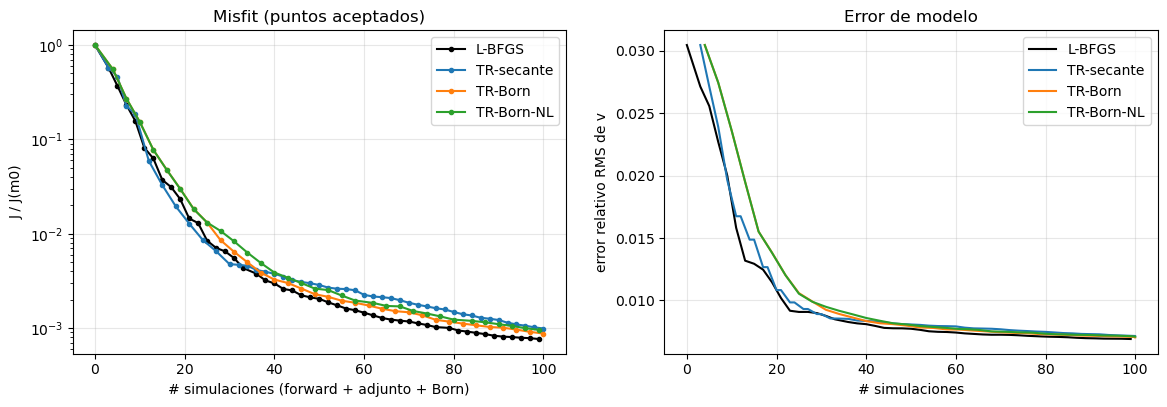

método        J final/J0  err final   fwd   adj  born
L-BFGS            0.0008     0.0069    51    49     0
TR-secante        0.0010     0.0071    54    46     0
TR-Born           0.0009     0.0070    34    33    33
TR-Born-NL        0.0010     0.0071    35    33    32


In [13]:
J_init = ExpensiveSolver(d_obs).forward(v_init)[0]
colors = {"L-BFGS": "k", "TR-secante": "tab:blue", "TR-Born": "tab:orange", "TR-Born-NL": "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for lab, R in results.items():
    if lab == "L-BFGS":
        xs = [0] + [e["sims"] for e in R["log"]]; Js = [J_init] + [e["J"] for e in R["log"]]
    else:
        acc = [e for e in R["log"] if e["accepted"]]
        xs = [0] + [e["sims"] for e in acc]; Js = [J_init] + [e["J_trial"] for e in acc]
    ax[0].semilogy(xs, np.array(Js) / J_init, "-o", ms=3, color=colors[lab], label=lab)
ax[0].set_xlabel("# simulaciones (forward + adjunto + Born)"); ax[0].set_ylabel("J / J(m0)")
ax[0].legend(); ax[0].grid(alpha=0.3); ax[0].set_title("Misfit (puntos aceptados)")
# error de modelo: usamos el registro 'err' que es el error en m_k al inicio de cada iteración
for lab, R in results.items():
    if lab == "L-BFGS":
        xs = [0] + [e["sims"] for e in R["log"]]; ys = [rel_err(v_init)] + [e["err"] for e in R["log"]]
    else:
        xs = [e["sims"] for e in R["log"]] + [R["solver"].n_sims]; ys = [e["err"] for e in R["log"]] + [R["err"]]
    ax[1].plot(xs, ys, "-", color=colors[lab], label=lab)
ax[1].set_xlabel("# simulaciones"); ax[1].set_ylabel("error relativo RMS de v"); ax[1].grid(alpha=0.3)
ax[1].legend(); ax[1].set_title("Error de modelo")
plt.show()

print(f"{'método':12s} {'J final/J0':>11s} {'err final':>10s} {'fwd':>5s} {'adj':>5s} {'born':>5s}")
for lab, R in results.items():
    s = R["solver"]
    print(f"{lab:12s} {R['J'] / J_init:11.4f} {R['err']:10.4f} {s.n_fwd:5d} {s.n_adj:5d} {s.n_born:5d}")

## 11. Dinámica de la región de confianza: $\rho_k$ y $\Delta_k$

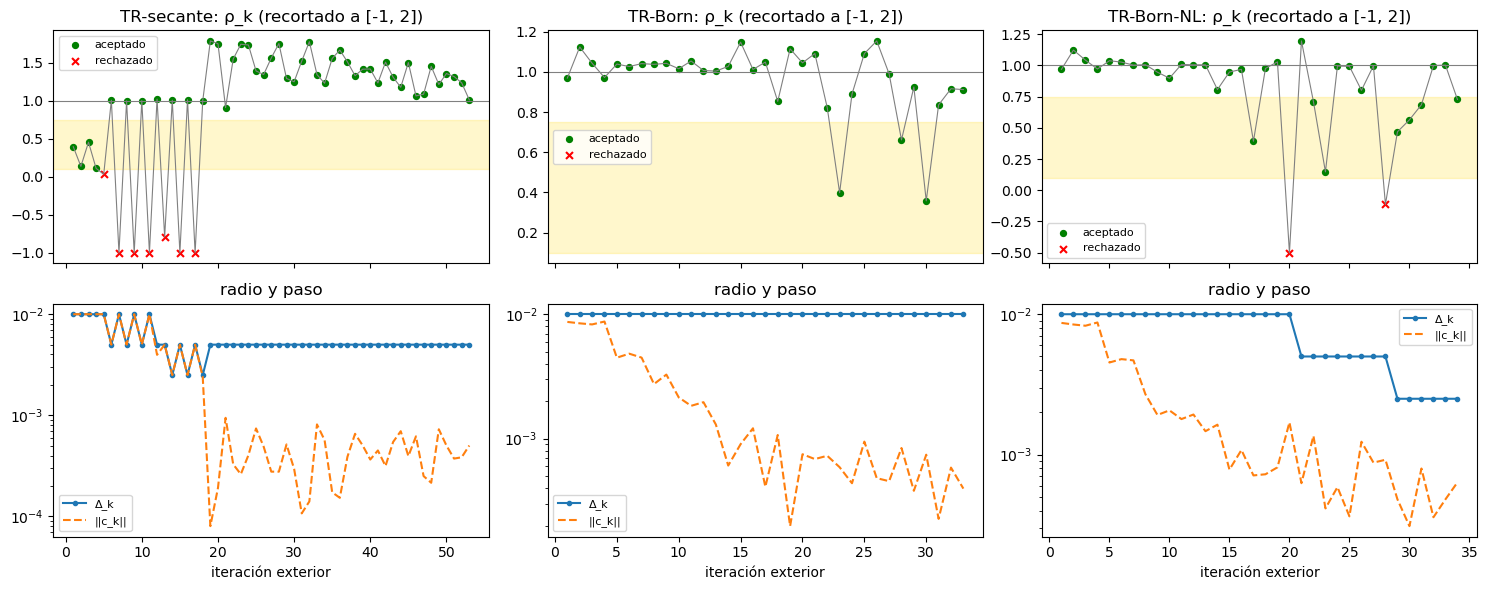

In [14]:
tr_labels = [l for l in results if l != "L-BFGS"]
fig, ax = plt.subplots(2, len(tr_labels), figsize=(5 * len(tr_labels), 6), sharex="col")
for j, lab in enumerate(tr_labels):
    L = results[lab]["log"]
    its = [e["it"] for e in L]
    rho = np.clip([e["rho"] for e in L], -1, 2)
    acc = np.array([e["accepted"] for e in L])
    ax[0, j].axhspan(0.1, 0.75, color="gold", alpha=0.2); ax[0, j].axhline(1, color="gray", lw=0.8)
    ax[0, j].plot(its, rho, "-", color="gray", lw=0.8)
    ax[0, j].scatter(np.array(its)[acc], rho[acc], c="g", s=18, label="aceptado")
    ax[0, j].scatter(np.array(its)[~acc], rho[~acc], c="r", marker="x", s=25, label="rechazado")
    ax[0, j].set_title(f"{lab}: ρ_k (recortado a [-1, 2])"); ax[0, j].legend(fontsize=8)
    ax[1, j].semilogy(its, [e["Delta"] for e in L], "-o", ms=3, label="Δ_k")
    ax[1, j].semilogy(its, [max(e["cnorm"], 1e-6) for e in L], "--", label="||c_k||")
    ax[1, j].set_xlabel("iteración exterior"); ax[1, j].legend(fontsize=8); ax[1, j].set_title("radio y paso")
plt.tight_layout(); plt.show()

## 12. Modelos finales

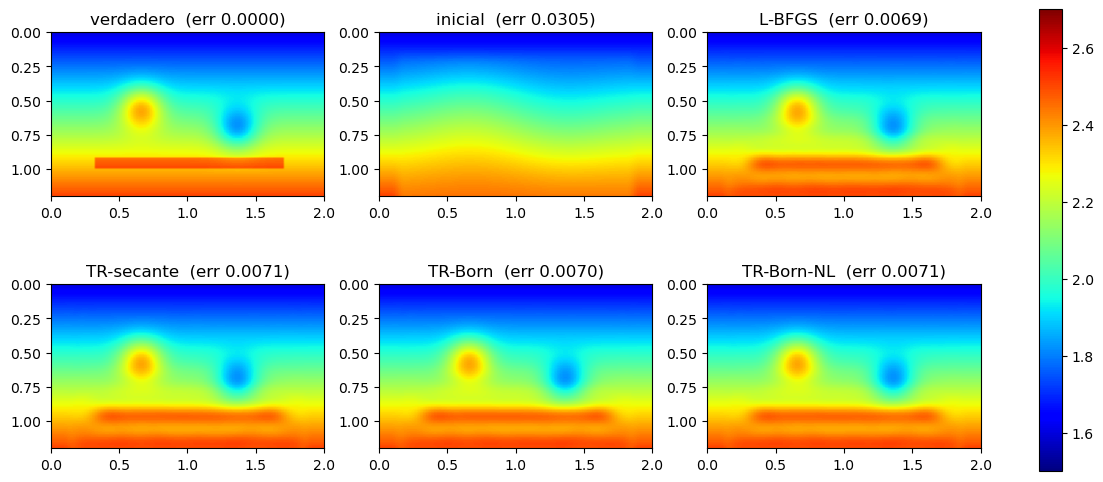

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
panels = [("verdadero", v_true), ("inicial", v_init)] + [(l, results[l]["m"]) for l in results]
for a, (ttl, mm) in zip(ax.flat, panels):
    im = a.imshow(mm.detach().cpu(), extent=ext, cmap="jet", vmin=1.5, vmax=2.7)
    a.set_title(f"{ttl}  (err {rel_err(mm):.4f})")
plt.colorbar(im, ax=ax); plt.show()

## 13. Calidad del surrogate: reducción predicha vs real

Si el surrogate fuera perfecto todos los puntos estarían en la diagonal ($\rho=1$). La región de confianza tolera
surrogates malos: simplemente rechaza y reduce $\Delta$.

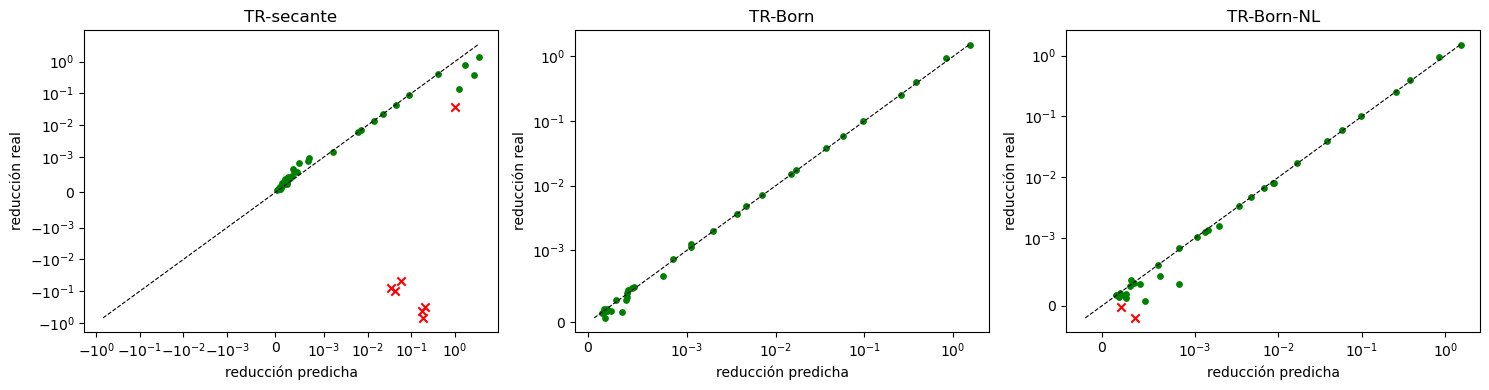

In [16]:
fig, ax = plt.subplots(1, len(tr_labels), figsize=(5 * len(tr_labels), 4))
for j, lab in enumerate(tr_labels):
    L = results[lab]["log"]
    pr = np.array([e["pred"] for e in L]); ar = np.array([e["ared"] for e in L])
    acc = np.array([e["accepted"] for e in L])
    ax[j].scatter(pr[acc], ar[acc], c="g", s=15); ax[j].scatter(pr[~acc], ar[~acc], c="r", marker="x")
    lim = [min(pr.min(), ar.min()), max(pr.max(), ar.max())]
    ax[j].plot(lim, lim, "k--", lw=0.8); ax[j].set_xscale("symlog", linthresh=1e-3); ax[j].set_yscale("symlog", linthresh=1e-3)
    ax[j].set_xlabel("reducción predicha"); ax[j].set_ylabel("reducción real"); ax[j].set_title(lab)
plt.tight_layout(); plt.show()

## 14. Experimentos adicionales (opcional)

Poner `RUN_EXTRA = True` para probar:
* **k más grande** (`kmax=20`): si los pasos aceptados quedan *dentro* de la bola ($\|c\|<\Delta$) con $\rho\approx1$,
  el limitante no es la región de confianza sino el subespacio.
* **Contabilidad conservadora** (`CHARGE_REFORWARD=True`): forward+adjunto=2 tras cada aceptación.

In [17]:
RUN_EXTRA = False
if RUN_EXTRA:
    results["TR-Born-k20"] = run_trust_region(TRConfig(budget=BUDGET, kmax=20, n_steps_basis=15, n_grads_basis=4,
                                                        use_born=True, verbose=False), label="TR-Born-k20")
    colors["TR-Born-k20"] = "tab:purple"
    R = results["TR-Born-k20"]
    print(f"TR-Born-k20: J/J0={R['J'] / J_init:.4f}  err={R['err']:.4f}")

## 15. Cómo leer los resultados

Observaciones de la ejecución de referencia (pueden variar con la semilla/GPU):

* **Consistencia de primer orden**: verificada numéricamente; $\nabla\tilde J_k(0)=g_c$ con $U,N_\phi$ aleatorios.
* **TR-secante** (sin Born): al principio $U$ apenas conoce las direcciones nuevas (solo $g_k$ y unas pocas secantes), así
  que hay rechazos alternados; cada rechazo es, de todas formas, un par $(s_k,\delta d_k)$ útil.
* **TR-Born**: la simulación Born en la dirección del gradiente da la columna de $U$ que falta, $\rho\approx1$ casi siempre
  y no hay rechazos; cuesta 1 simulación extra por iteración.
* **TR-Born-NL**: $N_\phi$ explica gran parte del residuo *de entrenamiento* (`nl↓`), pero con pocos pares sobreajusta;
  la región de confianza lo detecta ($\rho<\eta_1$), rechaza y reduce $\Delta$. Esto ilustra la propiedad de seguridad:
  un surrogate malo cuesta simulaciones, no convergencia.
* **Frente a L-BFGS**: con el mismo presupuesto, en este juguete las curvas son comparables. Con $\rho\approx1$ y pasos
  interiores, el cuello de botella es el **subespacio** (k) y que cada iteración exterior necesita forward+adjunto
  (+Born): el surrogate solo puede moverse en direcciones ya exploradas. El ahorro esperado aparecería si cada paso
  exterior lograra lo que varias iteraciones de L-BFGS, lo cual requiere que el subproblema interno explore más que
  el modelo cuadrático implícito de L-BFGS.

Ideas siguientes: subespacio más rico (gradientes por fuente/lote, direcciones Born adicionales, gradiente
precondicionado con pseudo-Hessiano), multi-banda con reinicio/reponderación del entrenamiento, ruido en los datos,
y ondícula desconocida.